# Задание 1. Функции активации и инициализация

Сеть — данная в задании `BaseNetwork`: четыре скрытых размера `[512, 256, 256, 128]`, после каждого скрытого линейного слоя стоит одна и та же функция активации, последний слой линейный и выдаёт 10 логитов.

Сравниваются три обязательные активации — ReLU, tanh и тождественная — и одна дополнительная, sigmoid. Инициализации одни и те же для всех активаций:

| имя | что делает |
| --- | --- |
| `zeros` | все веса и смещения равны 0 |
| `constant` | каждый вес равен 0.1, смещения равны 0 |
| `normal` | веса из N(0, 1), смещения равны 0 |
| `xavier` | `xavier_normal_`, смещения равны 0 |
| `kaiming` | `kaiming_normal_` с `nonlinearity="relu"`, смещения равны 0 |

Kaiming считается в режиме ReLU даже на tanh, sigmoid и identity. Так видно, что инициализация, согласованная с одной активацией, не обязана подойти другой. Смещения обнулены везде, чтобы сдвиг не маскировал масштаб весов.

Дальше два эксперимента. Сначала один и тот же батч прогоняется вперёд и назад: на выходе каждого слоя смотрим распределение активаций и распределение градиента потери по этому выходу. Потом те же пары «активация + инициализация» обучаются SGD на FashionMNIST с одним и тем же шагом.


In [ ]:
%matplotlib inline

import math

import pandas as pd
import torch
from matplotlib import pyplot as plt
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)


device: cpu


## Данные

FashionMNIST, картинки 28×28. `ToTensor` даёт яркость в `[0, 1]`, затем яркость переводится в примерно `[-1, 1]` вычитанием 0.5 и делением на 0.5. У сырых пикселей среднее далеко от нуля, и любая инициализация, рассчитанная на входы с нулевым средним, на них врёт. Обучающая и тестовая выборки читаются одним преобразованием.


In [2]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)
train_ds = datasets.FashionMNIST(root="data", train=True, download=True, transform=transform)
test_ds = datasets.FashionMNIST(root="data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=512)

probe_images, probe_labels = next(iter(train_loader))
probe_images = probe_images.to(device)
probe_labels = probe_labels.to(device)
print(tuple(probe_images.shape), "mean", float(probe_images.mean()), "std", float(probe_images.std()))


(256, 1, 28, 28) mean -0.42394787073135376 std 0.7221933007240295


## Сеть и инициализации

Класс скопирован из условия. Один и тот же объект активации стоит после каждого скрытого слоя: у ReLU, tanh, sigmoid и identity нет параметров, поэтому общее использование модуля ничего не портит. `forward` сначала вытягивает картинку в вектор.


In [3]:
class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=(512, 256, 256, 128)):
        super().__init__()
        layers = []
        layer_sizes = [input_size] + list(hidden_sizes)
        for layer_index in range(1, len(layer_sizes)):
            layers += [
                nn.Linear(layer_sizes[layer_index - 1], layer_sizes[layer_index]),
                act_fn,
            ]
        layers += [nn.Linear(layer_sizes[-1], num_classes)]
        self.layers = nn.ModuleList(layers)
        self.config = {
            "act_fn": act_fn.__class__.__name__,
            "input_size": input_size,
            "num_classes": num_classes,
            "hidden_sizes": list(hidden_sizes),
        }

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for layer in self.layers:
            x = layer(x)
        return x


LAYER_NAMES = ["fc1", "act1", "fc2", "act2", "fc3", "act3", "fc4", "act4", "logits"]
ACTIVATIONS = {
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh,
    "Identity": nn.Identity,
    "Sigmoid": nn.Sigmoid,
}
INITIALIZERS = ["zeros", "constant", "normal", "xavier", "kaiming"]


def apply_init(module, name):
    for layer in module.modules():
        if not isinstance(layer, nn.Linear):
            continue
        if name == "zeros":
            nn.init.zeros_(layer.weight)
            nn.init.zeros_(layer.bias)
        elif name == "constant":
            nn.init.constant_(layer.weight, 0.1)
            nn.init.zeros_(layer.bias)
        elif name == "normal":
            nn.init.normal_(layer.weight, mean=0.0, std=1.0)
            nn.init.zeros_(layer.bias)
        elif name == "xavier":
            nn.init.xavier_normal_(layer.weight)
            nn.init.zeros_(layer.bias)
        elif name == "kaiming":
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
        else:
            raise ValueError(name)


def make_model(activation_name, init_name):
    torch.manual_seed(0)
    model = BaseNetwork(ACTIVATIONS[activation_name]()).to(device)
    apply_init(model, init_name)
    return model


example = make_model("ReLU", "xavier")
print(example.config)
print("параметров:", sum(parameter.numel() for parameter in example.parameters()))


{'act_fn': 'ReLU', 'input_size': 784, 'num_classes': 10, 'hidden_sizes': [512, 256, 256, 128]}
параметров: 633226


## Активации и градиенты на одном батче

Для каждой пары берётся свежая сеть и фиксированный батч из 256 картинок. Потеря — кросс-энтропия по настоящим меткам, то есть градиент такой же, как на первом шаге обучения, а не искусственный градиент вида «единица на каждый логит».

После каждого слоя тензор помечается `retain_grad`, затем вызывается `backward`. В статистику попадает стандартное отклонение выхода слоя и стандартное отклонение `dL / d(выход)`. Отдельно считается доля «сломанных» координат последней скрытой активации: нули у ReLU, `|y| > 0.99` у tanh, хвосты `y < 0.01` или `y > 0.99` у sigmoid. Для гистограмм сохраняется подвыборка значений, чтобы не тащить весь тензор в рисунок.


In [4]:
loss_fn = nn.CrossEntropyLoss()


def subsample(values, size=4000):
    flat = values.detach().flatten().cpu()
    if flat.numel() > size:
        index = torch.randint(flat.numel(), (size,))
        flat = flat[index]
    return flat


def saturation_rate(activation_name, values):
    if activation_name == "ReLU":
        return float((values == 0).float().mean())
    if activation_name == "Tanh":
        return float((values.abs() > 0.99).float().mean())
    if activation_name == "Sigmoid":
        return float(((values < 0.01) | (values > 0.99)).float().mean())
    return float("nan")


def describe(activation_name, init_name):
    model = make_model(activation_name, init_name)
    model.zero_grad(set_to_none=True)
    features = probe_images.view(probe_images.size(0), -1)
    saved = []
    for layer in model.layers:
        features = layer(features)
        features.retain_grad()
        saved.append(features)
    loss = loss_fn(features, probe_labels)
    loss.backward()

    act_std, grad_std = [], []
    act_sample, grad_sample = [], []
    for tensor in saved:
        act_std.append(float(tensor.detach().std(unbiased=False)))
        grad_std.append(float(tensor.grad.detach().std(unbiased=False)))
        act_sample.append(subsample(tensor))
        grad_sample.append(subsample(tensor.grad))
    return {
        "activation": activation_name,
        "init": init_name,
        "loss": float(loss.detach()),
        "act_std": act_std,
        "grad_std": grad_std,
        "act_sample": act_sample,
        "grad_sample": grad_sample,
        "dead_or_saturated": saturation_rate(activation_name, saved[7].detach()),
    }


def verdict(row):
    act_std = row["act_std"]
    grad_std = row["grad_std"]
    if not all(math.isfinite(value) for value in act_std + grad_std) or max(act_std) > 100:
        return "взрыв активаций"
    if max(act_std) < 1e-6:
        return "активации нулевые"
    # У ReLU доля нулей около 1/2 — обычный режим, а не насыщение.
    if row["activation"] in {"Tanh", "Sigmoid"} and row["dead_or_saturated"] > 0.5:
        return "насыщение, градиент умирает"
    if grad_std[0] < grad_std[-1] * 1e-2:
        return "градиент затухает к входу"
    return "масштаб держится"


records = []
for activation_name in ACTIVATIONS:
    for init_name in INITIALIZERS:
        row = describe(activation_name, init_name)
        row["verdict"] = verdict(row)
        records.append(row)
        print(
            f"{activation_name:10} {init_name:10} "
            f"loss={row['loss']:.3f}  "
            f"std act {row['act_std'][0]:.2e} -> {row['act_std'][7]:.2e}  "
            f"std grad {row['grad_std'][0]:.2e} -> {row['grad_std'][-1]:.2e}  "
            f"{row['verdict']}"
        )


ReLU       zeros      loss=2.303  std act 0.00e+00 -> 0.00e+00  std grad 0.00e+00 -> 1.17e-03  активации нулевые
ReLU       constant   loss=2.303  std act 2.01e+01 -> 8.05e+04  std grad 5.42e-08 -> 1.17e-03  взрыв активаций
ReLU       normal     loss=755458.062  std act 2.37e+01 -> 2.79e+04  std grad 3.51e+00 -> 1.66e-03  взрыв активаций
ReLU       xavier     loss=2.335  std act 9.31e-01 -> 2.52e-01  std grad 6.69e-05 -> 1.18e-03  масштаб держится
ReLU       kaiming    loss=2.918  std act 1.20e+00 -> 6.88e-01  std grad 1.68e-04 -> 1.32e-03  масштаб держится
Tanh       zeros      loss=2.303  std act 0.00e+00 -> 0.00e+00  std grad 0.00e+00 -> 1.17e-03  активации нулевые
Tanh       constant   loss=2.303  std act 2.01e+01 -> 4.98e-01  std grad 0.00e+00 -> 1.17e-03  насыщение, градиент умирает
Tanh       normal     loss=15.597  std act 2.37e+01 -> 9.73e-01  std grad 1.19e-02 -> 1.57e-03  насыщение, градиент умирает
Tanh       xavier     loss=2.365  std act 9.31e-01 -> 4.19e-01  std grad 1.1

In [5]:
summary = pd.DataFrame(
    [
        {
            "activation": row["activation"],
            "init": row["init"],
            "loss": row["loss"],
            "act_std_first": row["act_std"][0],
            "act_std_last_hidden": row["act_std"][7],
            "grad_std_first": row["grad_std"][0],
            "grad_std_logits": row["grad_std"][-1],
            "dead_or_saturated": row["dead_or_saturated"],
            "verdict": row["verdict"],
        }
        for row in records
    ]
)
summary


,activation,init,loss,act_std_first,act_std_last_hidden,grad_std_first,grad_std_logits,dead_or_saturated,verdict
0,ReLU,zeros,2.302585e+00,0.000000,0.000000,0.000000e+00,0.001172,1.000000,активации нулевые
1,ReLU,constant,2.302585e+00,20.144047,80472.210938,5.415344e-08,0.001172,0.933594,взрыв активаций
2,ReLU,normal,7.554581e+05,23.694445,27884.572266,3.510841e+00,0.001656,0.535370,взрыв активаций
3,ReLU,xavier,2.334619e+00,0.930806,0.252139,6.691316e-05,0.001177,0.535370,масштаб держится
4,ReLU,kaiming,2.918325e+00,1.196750,0.687687,1.681475e-04,0.001319,0.535370,масштаб держится
5,Tanh,zeros,2.302585e+00,0.000000,0.000000,0.000000e+00,0.001172,0.000000,активации нулевые
6,Tanh,constant,2.302585e+00,20.144047,0.497982,0.000000e+00,0.001172,1.000000,"насыщение, градиент умирает"
7,Tanh,normal,1.559670e+01,23.694445,0.972935,1.192949e-02,0.001572,0.864380,"насыщение, градиент умирает"
8,Tanh,xavier,2.365091e+00,0.930806,0.418843,1.163339e-04,0.001182,0.000000,масштаб держится
9,Tanh,kaiming,2.443584e+00,1.196750,0.580956,1.560536e-04,0.001194,0.001099,масштаб держится


## Графики по глубине

На рисунке по вертикали `log10` стандартного отклонения. Ноль на оси — это std около 1, то есть величины, с которыми линейный слой и кросс-энтропия нормально работают. Уход вверх — взрыв, уход вниз — затухание. Слева активации, справа градиенты по выходу слоя. Слои слева направо: `fc1`, `act1`, …, `logits`.

Гистограммы ниже показывают форму, которую одно число std прячет. У насыщенной tanh std ещё может быть порядка единицы, но масса значений сидит на ±1. Пределы каждой гистограммы — перцентили 1 и 99, иначе один выброс схлопывает рисунок в столбик; масштаб при этом виден на кривых `log10 std`.


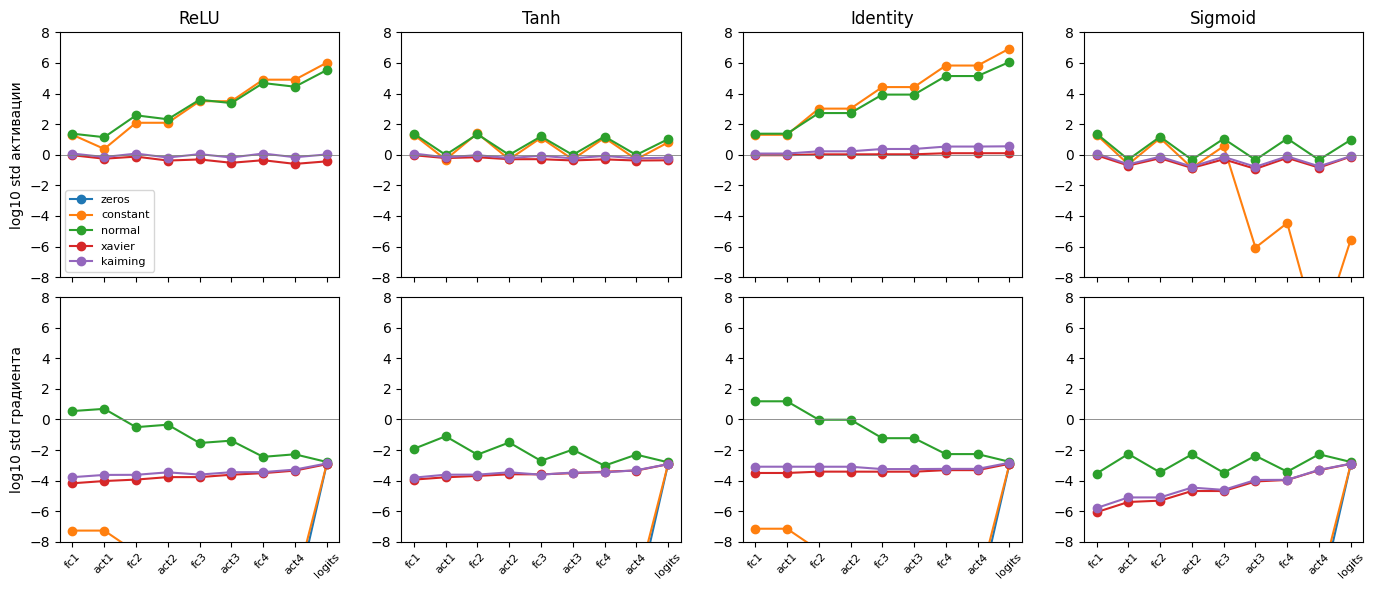

In [6]:
def plot_std_curves(rows):
    fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
    for column, activation_name in enumerate(ACTIVATIONS):
        for row in rows:
            if row["activation"] != activation_name:
                continue
            axes[0, column].plot(
                range(len(LAYER_NAMES)),
                [torch.log10(torch.tensor(value + 1e-12)).item() for value in row["act_std"]],
                marker="o",
                label=row["init"],
            )
            axes[1, column].plot(
                range(len(LAYER_NAMES)),
                [torch.log10(torch.tensor(value + 1e-12)).item() for value in row["grad_std"]],
                marker="o",
                label=row["init"],
            )
        axes[0, column].set_title(activation_name)
        axes[0, column].axhline(0.0, color="gray", linewidth=0.6)
        axes[1, column].axhline(0.0, color="gray", linewidth=0.6)
        axes[1, column].set_xticks(range(len(LAYER_NAMES)), LAYER_NAMES, rotation=45, fontsize=8)
        axes[0, column].set_ylim(-8, 8)
        axes[1, column].set_ylim(-8, 8)
    axes[0, 0].set_ylabel("log10 std активации")
    axes[1, 0].set_ylabel("log10 std градиента")
    axes[0, 0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


plot_std_curves(records)


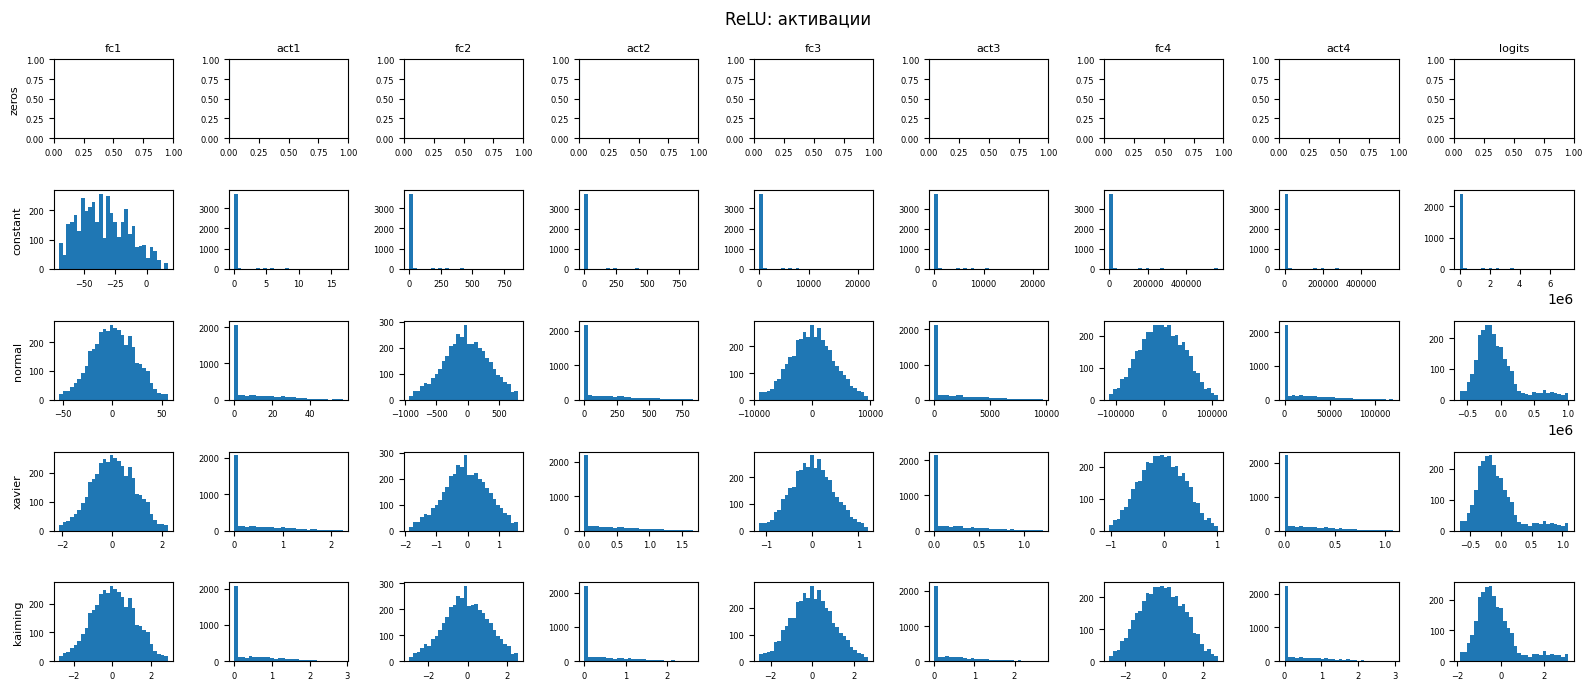

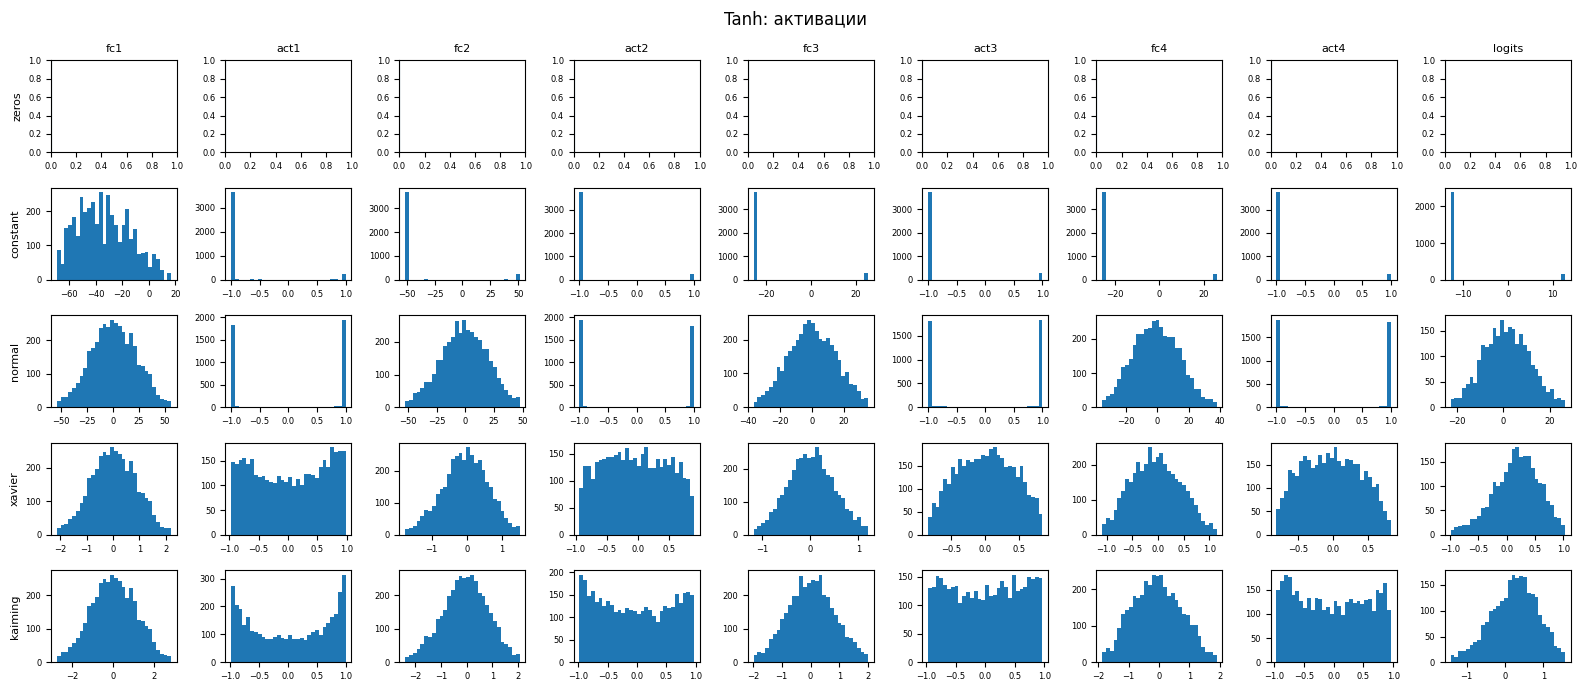

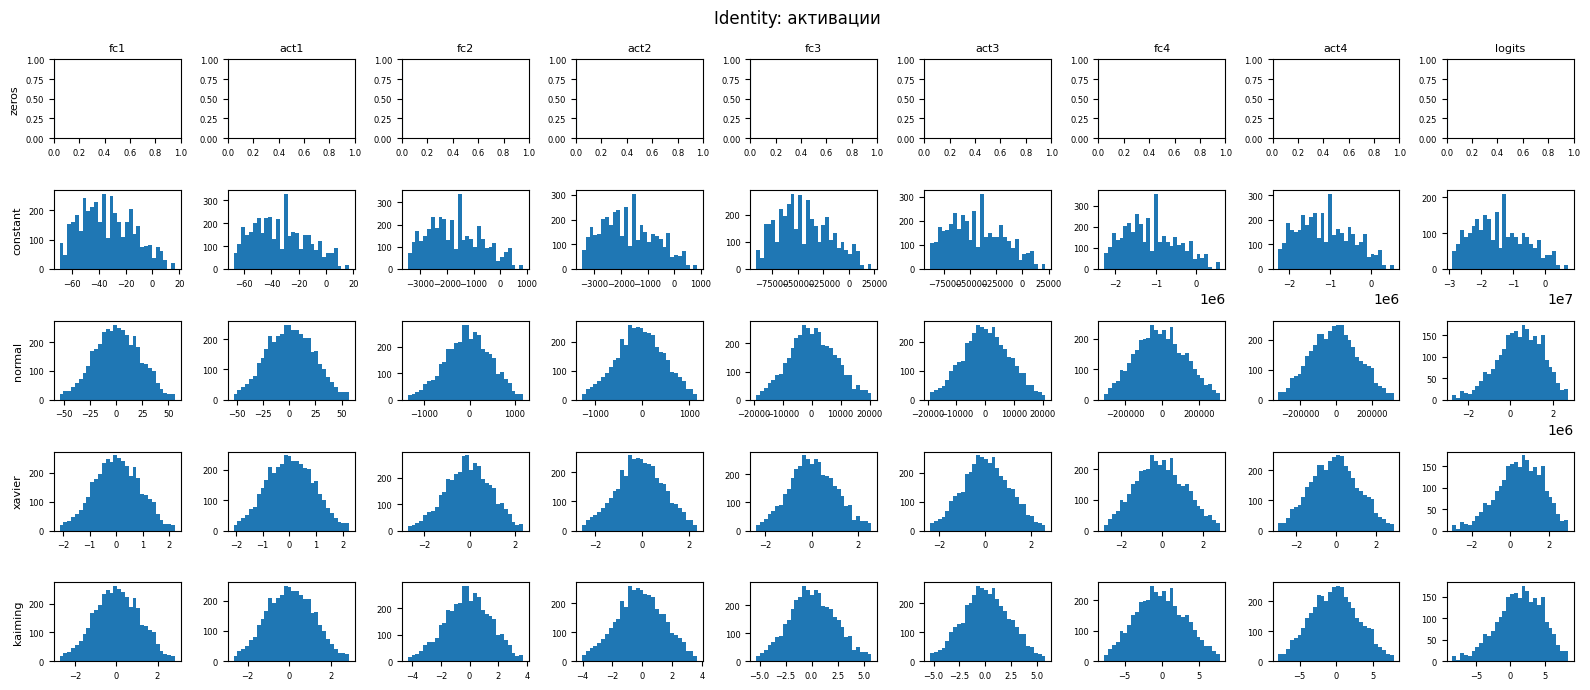

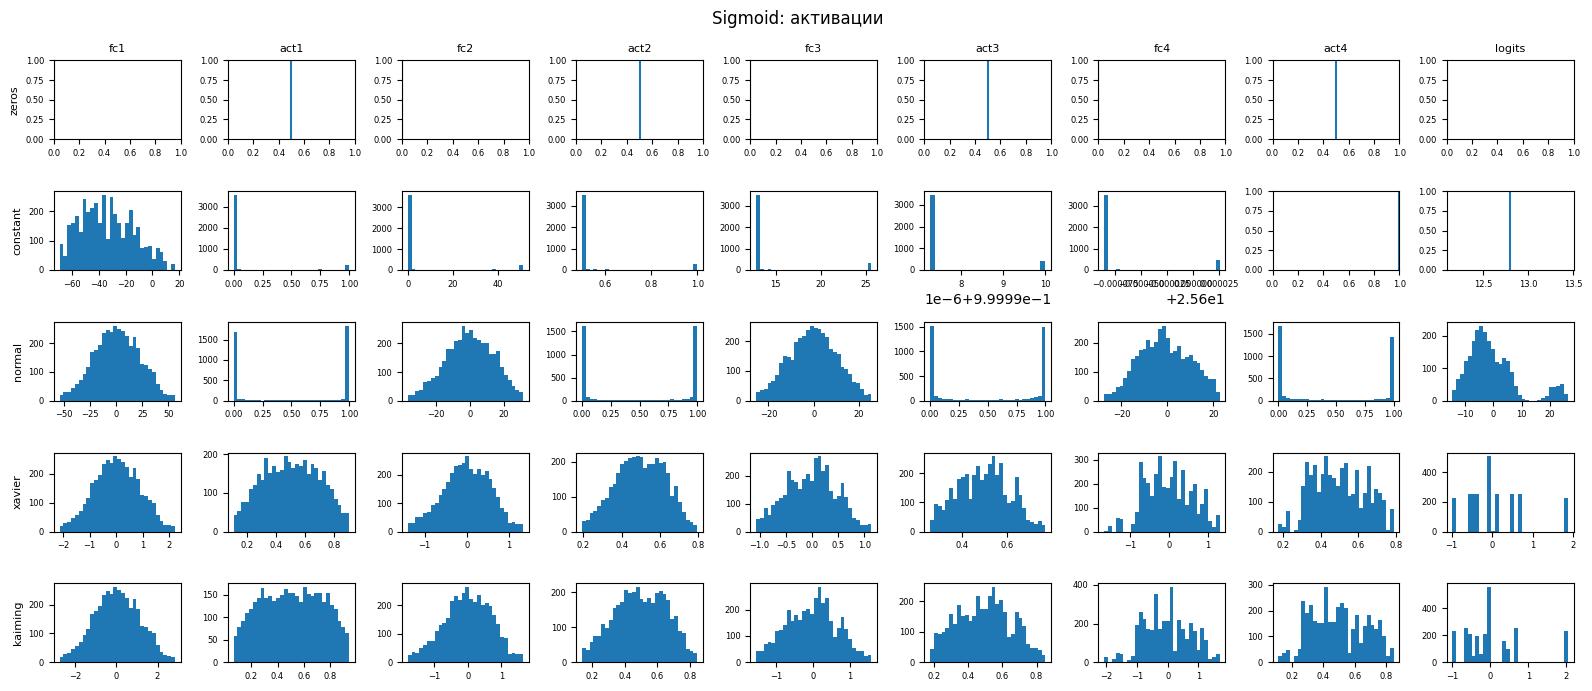

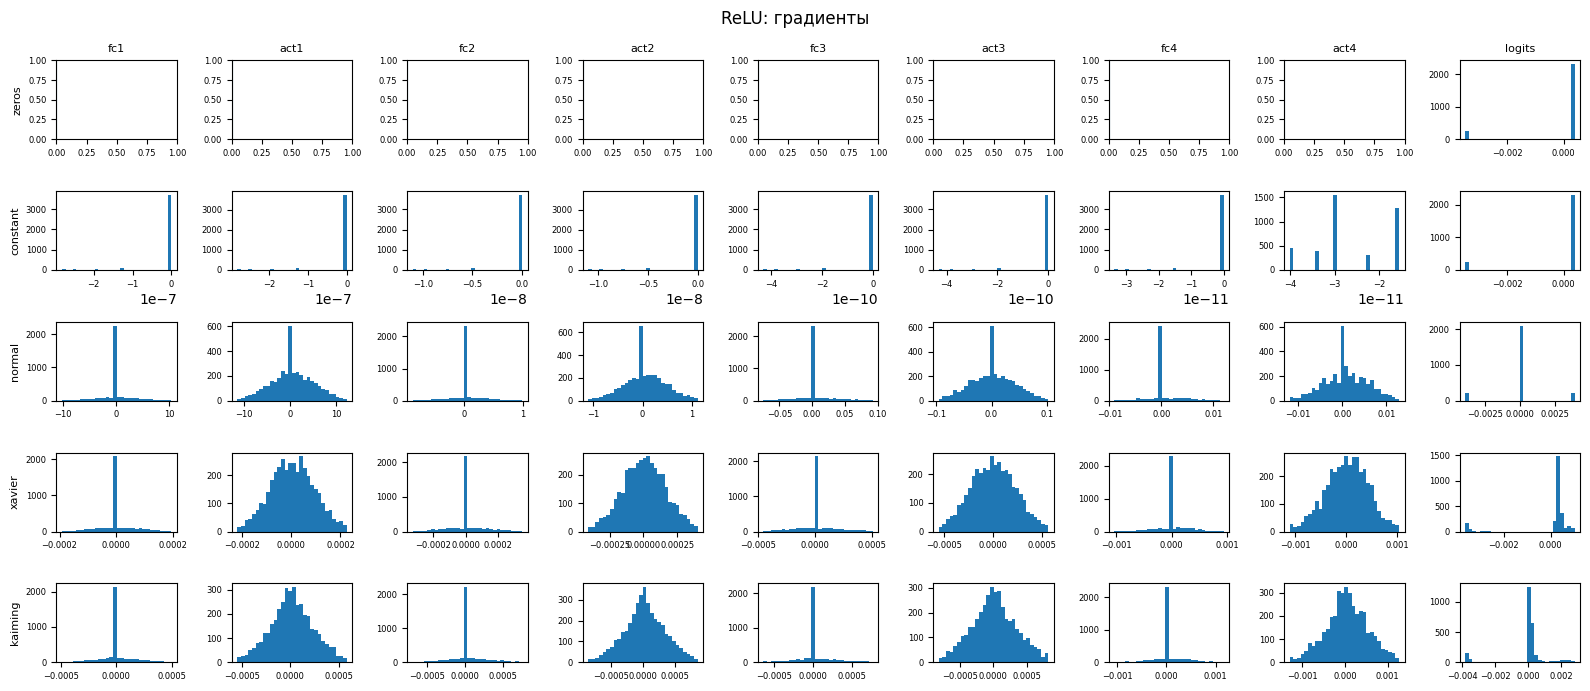

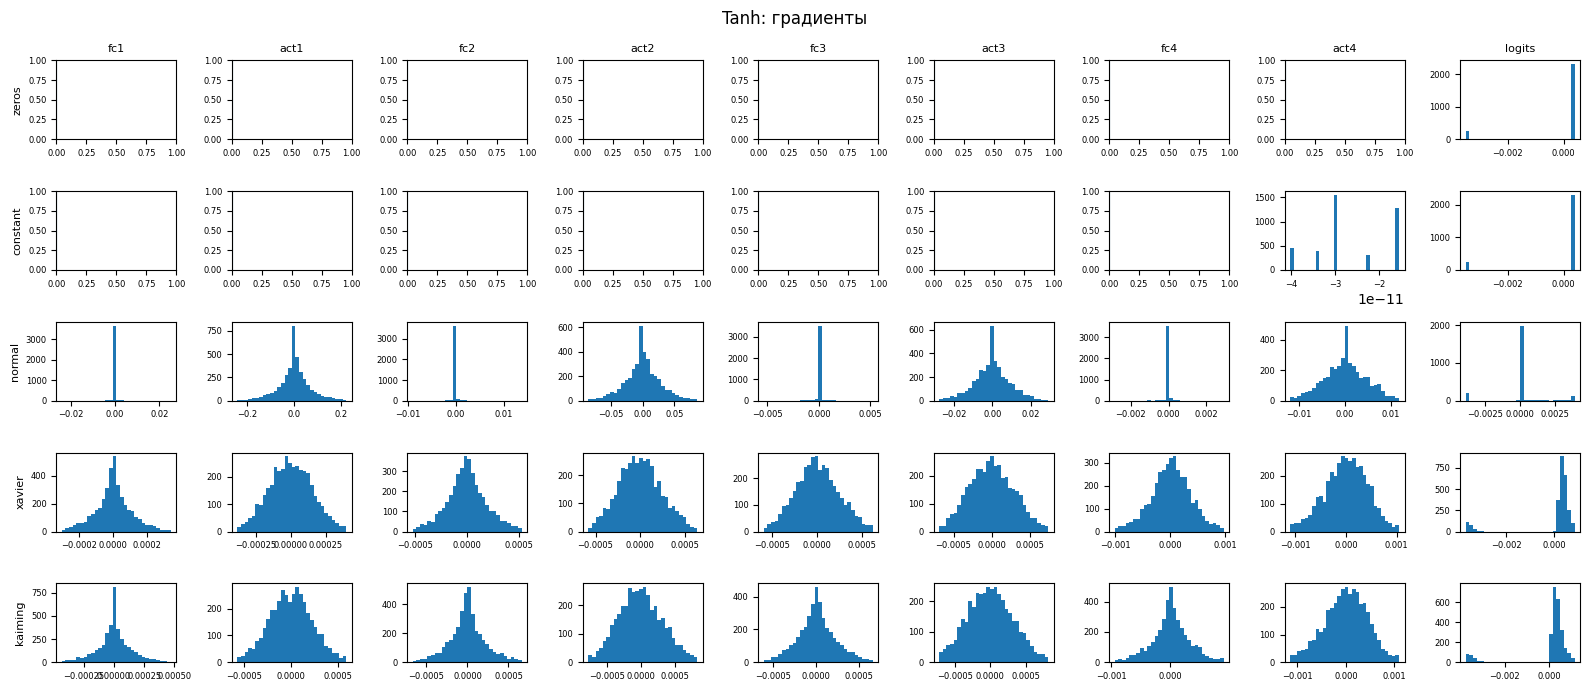

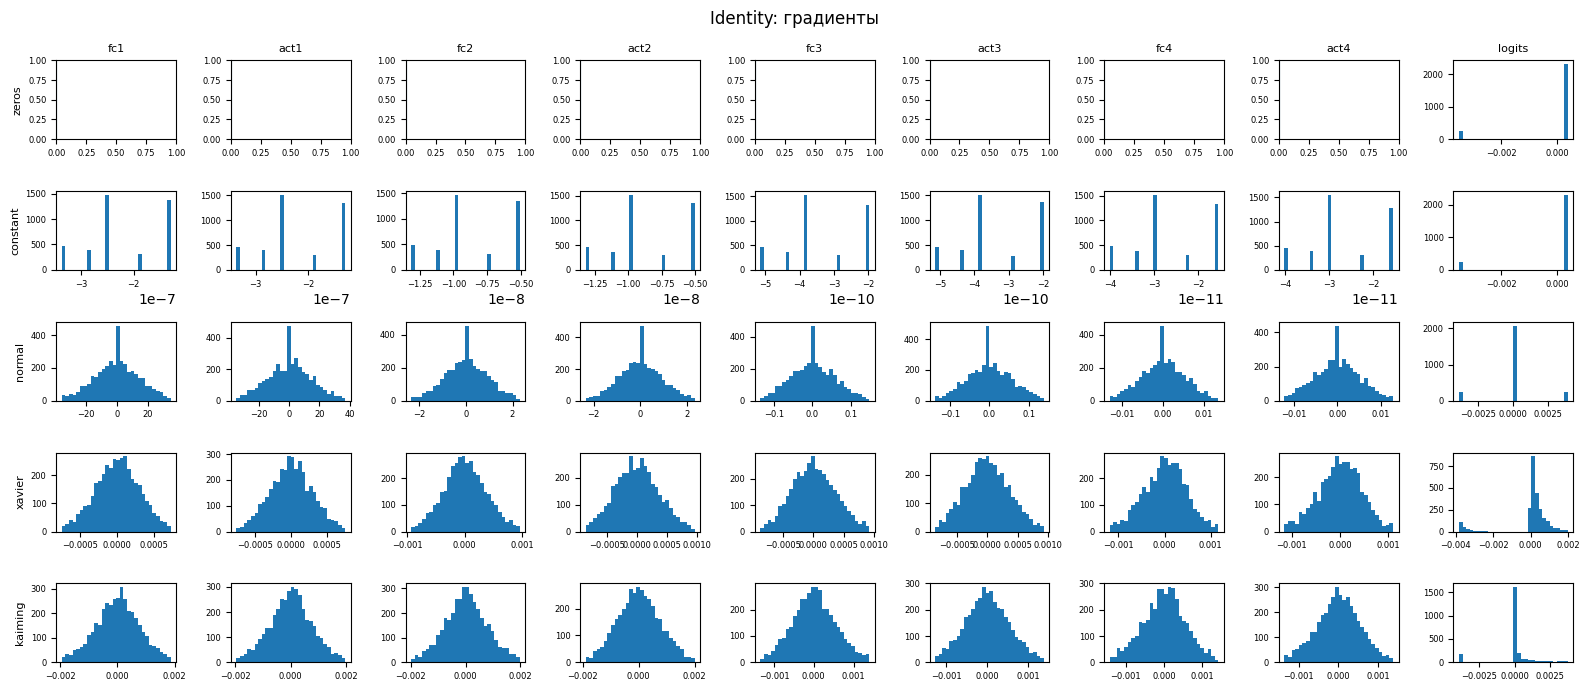

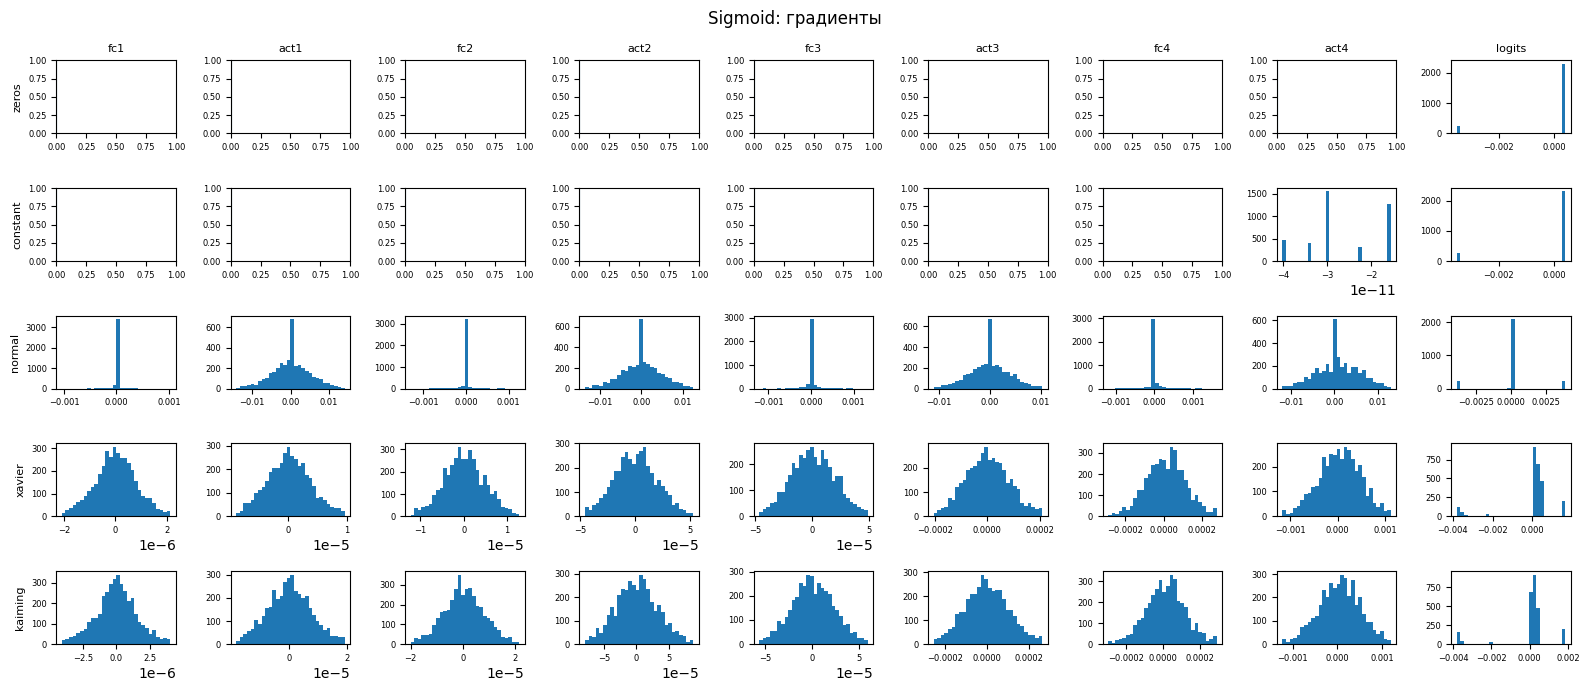

In [7]:
def plot_histograms(rows, kind):
    for activation_name in ACTIVATIONS:
        selected = [row for row in rows if row["activation"] == activation_name]
        fig, axes = plt.subplots(
            len(selected),
            len(LAYER_NAMES),
            figsize=(16, 7),
            squeeze=False,
        )
        for row_index, row in enumerate(selected):
            samples = row["act_sample"] if kind == "activation" else row["grad_sample"]
            for column, values in enumerate(samples):
                axis = axes[row_index, column]
                array = values.numpy()
                finite = array[torch.isfinite(values).numpy()] if array.size else array
                if finite.size == 0 or float(finite.max()) - float(finite.min()) < 1e-12:
                    center = 0.0 if finite.size == 0 else float(finite[0])
                    axis.axvline(center, color="C0")
                else:
                    low, high = torch.quantile(torch.tensor(finite), torch.tensor([0.01, 0.99])).tolist()
                    if low == high:
                        low, high = low - 1.0, high + 1.0
                    axis.hist(finite, bins=30, range=(low, high), color="C0")
                if row_index == 0:
                    axis.set_title(LAYER_NAMES[column], fontsize=8)
                if column == 0:
                    axis.set_ylabel(row["init"], fontsize=8)
                axis.tick_params(labelsize=6)
        fig.suptitle(f"{activation_name}: {'активации' if kind == 'activation' else 'градиенты'}")
        fig.tight_layout()
        plt.show()


plot_histograms(records, "activation")
plot_histograms(records, "gradient")


## Какая инициализация держит масштаб

**ReLU.** Устойчивы Xavier и Kaiming. Kaiming для ReLU как раз и выведен: дисперсия весов `2 / fan_in` компенсирует то, что ReLU обнуляет отрицательную половину. На кривой std скрытых активаций остаётся около 1. Xavier тоже не разваливается, но дисперсию понемногу сжимает — он этого обнуления не закладывает. Около половины координат на последнем ReLU равны нулю и у того, и у другого: для ReLU это нормальный режим, а не поломка. Нулевая инициализация оставляет все активации нулевыми, градиент по скрытым весам тоже ноль, потому что на вход следующего слоя приходит ноль. Константа 0.1 и N(0, 1) разгоняют активации до десятков тысяч: при `fan_in = 784` дисперсия предактивации равна `fan_in * std(w)^2`, для N(0, 1) это уже сотни. Градиент при таком масштабе на первых слоях либо крошечный, либо сам огромный.

**tanh.** Согласованная схема — Xavier: и активации, и градиенты остаются одного порядка по всей глубине, насыщения (`|y| > 0.99`) нет. Kaiming тоже не сатурирует эту сеть, запас по масштабу больше нужного, но за четыре скрытых слоя tanh ещё не упирается в ±1. Константа и N(0, 1) загоняют tanh в насыщение: на последней активации 86–100% координат лежат у ±1, производная там почти ноль, и градиент до начала сети не доходит. Нулевая инициализация мертва так же, как у ReLU.

**Identity.** Это глубокая линейная сеть, нелинейность масштаб не спасает и не режет. Xavier сохраняет std около 1 от первого слоя до логитов — для линейного случая он и designed. Kaiming умножает дисперсию на лишний `2` на каждом слое, std растёт примерно с 1.2 до 3.5. Это ещё не взрыв, но уже хуже Xavier. Константа и N(0, 1) доводят std до `1e5–1e6`. Нулевая инициализация снова даёт тождественный ноль.

**Sigmoid, дополнительная функция.** Отдельной удачной инициализации здесь нет. Xavier и Kaiming держат сами активации конечными и без жёсткого насыщения, но производная sigmoid не больше 0.25. Из-за этого std градиента падает от порядка `1e-3` на логитах до `1e-6` на первом слое: формально числа живые, практически ранние слои почти не обучаются. Константа и N(0, 1) сатурируют sigmoid так же, как tanh. Нулевая инициализация даёт на выходе sigmoid константу 0.5. Для глубокой сети sigmoid проигрывает tanh даже при лучшей из этих инициализаций: у tanh в рабочей зоне производная близка к 1, у sigmoid она заведомо меньше четверти.


## Сходимость на FashionMNIST, SGD

Те же 20 сетей. Оптимизатор — SGD без момента, `lr = 1e-2`, размер батча 256, 10 эпох. Шаг специально один и тот же: иначе непонятно, что именно улучшило кривую, инициализация или подобранный шаг. Порядок батчей фиксирован генератором с seed 0.

Если потеря перестаёт быть числом, прогон останавливается. Для N(0, 1) и константы это ожидаемо: норма градиента по параметрам там на порядки больше, и один шаг SGD уносит веса. Такая остановка и есть результат сравнения, а не сбой цикла.


In [8]:
def evaluate(model):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            predicted = model(images).argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    return correct / total


def train_one(activation_name, init_name, epochs=10, lr=1e-2):
    model = make_model(activation_name, init_name)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(0)
    loader = DataLoader(train_ds, batch_size=256, shuffle=True, generator=generator)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        seen = 0
        finite = True
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            loss = loss_fn(model(images), labels)
            if not torch.isfinite(loss):
                finite = False
                break
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += float(loss.detach()) * images.size(0)
            seen += images.size(0)
        if not finite or seen == 0:
            history.append({"epoch": epoch, "train_loss": float("nan"), "test_accuracy": float("nan")})
            break
        accuracy = evaluate(model)
        history.append(
            {
                "epoch": epoch,
                "train_loss": total_loss / seen,
                "test_accuracy": accuracy,
            }
        )
    return history


runs = {}
for activation_name in ACTIVATIONS:
    for init_name in INITIALIZERS:
        history = train_one(activation_name, init_name)
        runs[(activation_name, init_name)] = history
        last = history[-1]
        print(
            f"{activation_name:10} {init_name:10} "
            f"epochs={len(history):2d}  "
            f"train_loss={last['train_loss']:.4f}  "
            f"test_accuracy={last['test_accuracy']:.3f}"
        )


ReLU       zeros      epochs=10  train_loss=2.3026  test_accuracy=0.100
ReLU       constant   epochs=10  train_loss=2.3026  test_accuracy=0.100
ReLU       normal     epochs= 1  train_loss=nan  test_accuracy=nan
ReLU       xavier     epochs=10  train_loss=0.3736  test_accuracy=0.851
ReLU       kaiming    epochs=10  train_loss=0.3436  test_accuracy=0.856
Tanh       zeros      epochs=10  train_loss=2.3026  test_accuracy=0.100
Tanh       constant   epochs=10  train_loss=2.2802  test_accuracy=0.117
Tanh       normal     epochs=10  train_loss=3.2736  test_accuracy=0.528
Tanh       xavier     epochs=10  train_loss=0.3823  test_accuracy=0.850
Tanh       kaiming    epochs=10  train_loss=0.3588  test_accuracy=0.857
Identity   zeros      epochs=10  train_loss=2.3026  test_accuracy=0.100
Identity   constant   epochs= 1  train_loss=nan  test_accuracy=nan
Identity   normal     epochs= 1  train_loss=nan  test_accuracy=nan
Identity   xavier     epochs=10  train_loss=0.4212  test_accuracy=0.831
Identit

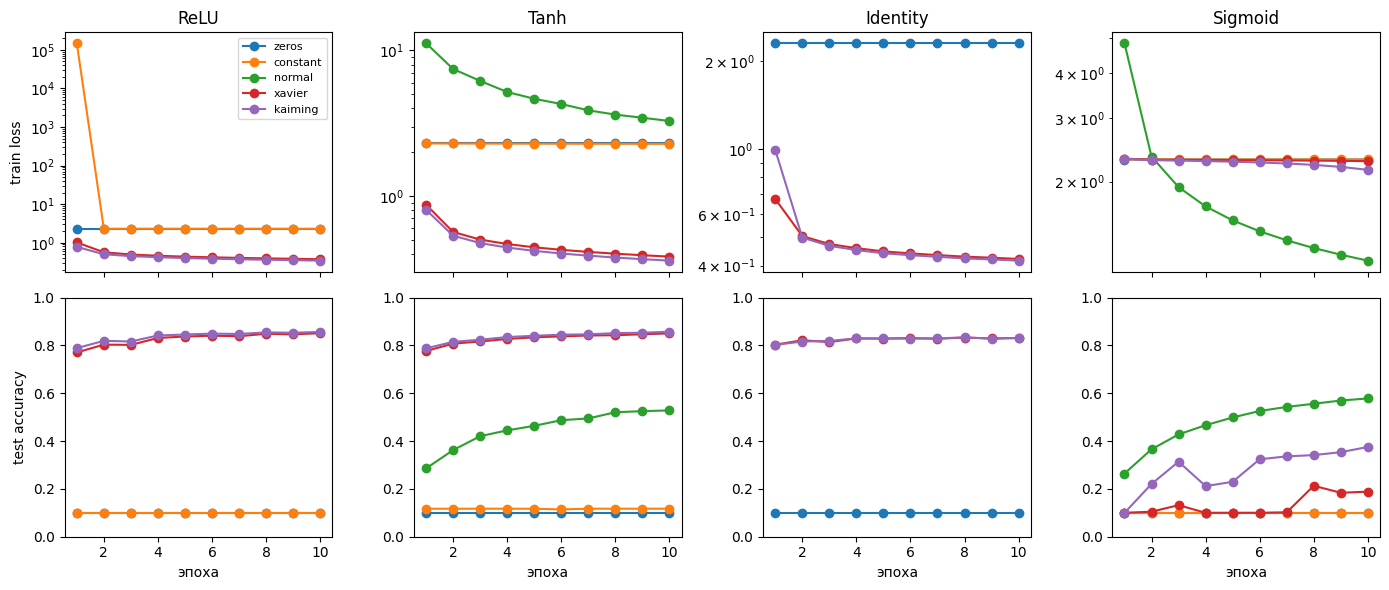

,activation,init,epochs_run,final_train_loss,best_test_accuracy,diverged
9,Tanh,kaiming,10,0.358781,0.8572,False
4,ReLU,kaiming,10,0.343572,0.8564,False
3,ReLU,xavier,10,0.373595,0.8511,False
8,Tanh,xavier,10,0.382324,0.8502,False
14,Identity,kaiming,10,0.415717,0.8335,False
13,Identity,xavier,10,0.421213,0.8328,False
17,Sigmoid,normal,10,1.210048,0.5782,False
7,Tanh,normal,10,3.273578,0.5282,False
19,Sigmoid,kaiming,10,2.156745,0.3753,False
18,Sigmoid,xavier,10,2.279820,0.2130,False


In [9]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
for column, activation_name in enumerate(ACTIVATIONS):
    for init_name in INITIALIZERS:
        history = runs[(activation_name, init_name)]
        epochs = [item["epoch"] for item in history]
        axes[0, column].plot(
            epochs,
            [item["train_loss"] for item in history],
            marker="o",
            label=init_name,
        )
        axes[1, column].plot(
            epochs,
            [item["test_accuracy"] for item in history],
            marker="o",
            label=init_name,
        )
    axes[0, column].set_title(activation_name)
    axes[0, column].set_yscale("log")
    axes[1, column].set_ylim(0.0, 1.0)
    axes[1, column].set_xlabel("эпоха")
axes[0, 0].set_ylabel("train loss")
axes[1, 0].set_ylabel("test accuracy")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

training_table = pd.DataFrame(
    [
        {
            "activation": activation_name,
            "init": init_name,
            "epochs_run": len(history),
            "final_train_loss": history[-1]["train_loss"],
            "best_test_accuracy": max(
                item["test_accuracy"]
                for item in history
                if item["test_accuracy"] == item["test_accuracy"]
            )
            if any(item["test_accuracy"] == item["test_accuracy"] for item in history)
            else float("nan"),
            "diverged": history[-1]["train_loss"] != history[-1]["train_loss"],
        }
        for (activation_name, init_name), history in runs.items()
    ]
)
training_table.sort_values("best_test_accuracy", ascending=False)


## Итог

Согласованная пара «активация + инициализация» видна и на распределениях, и в обучении.

На одном батче масштаб держат Xavier и Kaiming для ReLU, tanh и identity. Для ReLU ровнее Kaiming: std скрытых активаций остаётся около 1, у Xavier он сжимается с 0.93 до 0.25. Для tanh и identity ровнее Xavier; Kaiming на identity раздувает std с 1.2 до 3.4, но за четыре слоя это ещё не взрыв. Нулевая инициализация даёт нулевые активации. Константа 0.1 и N(0, 1) разгоняют линейный выход до десятков тысяч; tanh и sigmoid при этом сатурируются, и градиент в ранние слои не приходит. У sigmoid даже Xavier и Kaiming не спасают обратный проход: std градиента падает с `1e-3` на логитах до `1e-6` на первом слое.

SGD, `lr = 1e-2`, 10 эпох, лучшая test accuracy:

| активация | инициализация | accuracy |
| --- | --- | --- |
| tanh | Kaiming | 85.7% |
| ReLU | Kaiming | 85.6% |
| ReLU | Xavier | 85.1% |
| tanh | Xavier | 85.0% |
| identity | Kaiming | 83.4% |
| identity | Xavier | 83.3% |
| sigmoid | N(0, 1) | 57.8% |
| tanh | N(0, 1) | 52.8% |
| sigmoid | Kaiming | 37.5% |
| sigmoid | Xavier | 21.3% |

Остальные комбинации остаются около 10% либо получают NaN на первой эпохе (ReLU с N(0, 1), identity с константой и с N(0, 1)).

Два расхождения между видом loss и видом активаций стоит проговорить отдельно. У ReLU с константой 0.1 активации взрываются до std `8e4`, но все логиты равны между собой, softmax остаётся равномерным, и loss застывает на `log 10`. Кривая выглядит как у нулевой сети, хотя сеть не здоровая: это видно по std, а не по accuracy. У sigmoid Xavier как раз «правильная» по масштабу активаций схема, но из-за затухания градиента за 10 эпох она доходит только до 21%. N(0, 1) у sigmoid насыщена, однако градиент на первом слое там крупнее (`3e-4` против `9e-7`), поэтому accuracy ползёт до 58% и всё равно далеко от 85% у tanh и ReLU.

Практический вывод: для этой глубины и SGD без подбора шага рабочие пары — ReLU или tanh с Kaiming или Xavier. Identity с этими же инициализациями обучается, но без нелинейности потолок ниже, около 83%. Sigmoid в этот список не входит.
